## Problem 8
Write a Python program to apply gray-level slicing (with and without background).

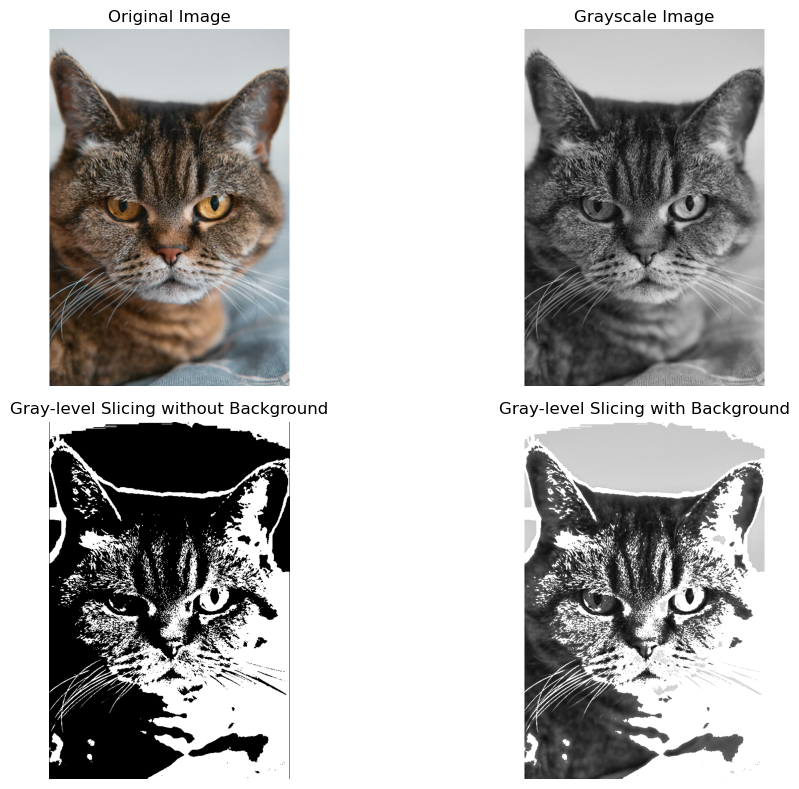

In [1]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

image = cv2.imread("cat.png")
height, width = image.shape[:2]
gray = np.zeros((height, width), dtype=np.uint8)
slice_without_background = np.zeros((height, width), dtype=np.uint8)
slice_with_background = np.zeros((height, width), dtype=np.uint8)

lower = 100
upper = 200

for row in range(height):
    for col in range(width):
        blue = int(image[row, col, 0])
        green = int(image[row, col, 1])
        red = int(image[row, col, 2])
        gray_value = int(0.114 * blue + 0.587 * green + 0.299 * red)
        gray[row, col] = gray_value

        # Without background: selected range becomes white, others black.
        if lower <= gray_value <= upper:
            slice_without_background[row, col] = 255
            slice_with_background[row, col] = 255
        else:
            slice_without_background[row, col] = 0
            # With background: keep the original gray value.
            slice_with_background[row, col] = gray_value

plt.figure(figsize=(12, 8))

plt.subplot(2, 2, 1)
plt.imshow(image[:, :, ::-1])
plt.title("Original Image")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(gray, cmap="gray")
plt.title("Grayscale Image")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(slice_without_background, cmap="gray")
plt.title("Gray-level Slicing without Background")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(slice_with_background, cmap="gray")
plt.title("Gray-level Slicing with Background")
plt.axis("off")

plt.tight_layout()
plt.show()
